In [2]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

def data(x):
    if not isinstance(x, str):
        return pd.Timestamp(x)
    for f in ("%Y-%m-%d", "%d/%m/%Y", "%d-%m-%y"):
        try:
            return pd.to_datetime(x.strip(), format=f)
        except ValueError:
            pass
    return pd.NaT

PUNTI = {
    "barriera": "PR01", "mirafiori": "PR02", "moncalieri": "PR03", "collegno": "PR04",
    "chieri": "PR05", "nichelino": "PR06", "venaria": "PR07"
}
NOMI_PUNTI = {
    "PR01": "PR01 - Barriera", "PR02": "PR02 - Mirafiori", "PR03": "PR03 - Moncalieri",
    "PR04": "PR04 - Collegno", "PR05": "PR05 - Chieri", "PR06": "PR06 - Nichelino",
    "PR07": "PR07 - Venaria"
}

def punto(x):
    x = str(x).strip().lower()
    if re.fullmatch(r"pr0[1-7]", x):
        return x.upper()
    return next((c for k, c in PUNTI.items() if k in x), None)

CAUSALI = {
    "scaduto": "scaduto", "scad.": "scaduto", "da scartare": "scaduto",
    "non idoneo": "non_idoneo", "danneggiato": "danneggiato", "rotto": "danneggiato"
}

CATEGORIE = {
    "pane": "Pane e prodotti da forno", "prodotti da forno": "Pane e prodotti da forno",
    "salumi": "Carne e affettati confezionati", "affettati": "Carne e affettati confezionati",
    "carne confezionata": "Carne e affettati confezionati", "frutta": "Frutta fresca",
    "verdure": "Verdura fresca", "verdura": "Verdura fresca", "ortaggi": "Verdura fresca",
    "latticini": "Latticini freschi", "formaggi/yogurt": "Latticini freschi", "yogurt": "Latticini freschi",
    "latte": "Latte UHT", "latte uht": "Latte UHT", "merendine": "Biscotti e merendine",
    "fagioli/ceci": "Legumi in scatola", "legumi scatola": "Legumi in scatola", "riso confezionato": "Riso"
}

def kg(x):
    t = str(x).lower().replace(",", ".")
    n = re.search(r"\d+(\.\d+)?", t)
    return float(n.group()) if n and "pz" not in t else None

# 1. Scarti
s = pd.read_excel("magazzino_giacenze_scarti.xlsx", sheet_name="Scarti")
s["data"] = s["data"].map(data)
s["punto_id"] = s["punto"].map(punto)
s["causale_ok"] = s["causale"].str.strip().str.lower().map(CAUSALI)
s["categoria"] = s["prodotto"].str.strip().map(lambda p: CATEGORIE.get(p.lower(), p))
s["kg"] = s["quantita"].map(kg)
s_kg = s.dropna(subset=["kg"]).copy()

# 2. Turni
t = pd.read_excel("turni_volontari.xlsx")
t["data"] = t["data"].map(data)
t["stato"] = t["stato"].str.strip().str.lower()
t["mese"] = t["data"].dt.to_period("M").astype(str)

# 3. Beneficiari
b = pd.read_excel("anagrafiche_buby_solidale.xlsx", sheet_name="Beneficiari anonimi")
attivi = b.drop_duplicates("id_beneficiario").query("stato_scheda == 'attiva'").copy()

In [3]:
righe = [
    ("Righe scarti in pezzi escluse", f"{s['kg'].isna().sum()} righe", "s['kg'].isna().sum()"),
    ("Kg scartati — Totale", f"{s['kg'].sum():.1f} kg", "s['kg'].sum()"),
]

for c, val in s_kg.groupby("causale_ok")["kg"].sum().sort_values(ascending=False).items():
    righe.append((f"Kg scartati — Causale: {c}", f"{val:.1f} kg ({val/s['kg'].sum():.1%})", f"s.loc[s['causale_ok']=='{c}', 'kg'].sum()"))

for cat, val in s_kg.groupby("categoria")["kg"].sum().sort_values(ascending=False).items():
    righe.append((f"Kg scartati — Categoria: {cat}", f"{val:.1f} kg ({val/s['kg'].sum():.1%})", f"s.loc[s['categoria']=='{cat}', 'kg'].sum()"))

for p, val in s_kg.groupby("punto_id")["kg"].sum().sort_values(ascending=False).items():
    righe.append((f"Kg scartati — Punto: {p}", f"{val:.1f} kg ({val/s['kg'].sum():.1%})", f"s.loc[s['punto_id']=='{p}', 'kg'].sum()"))

righe.append(("Quota turni scoperti — Totale", f"{(t['stato']=='scoperto').mean():.2%}", "(t['stato'] == 'scoperto').mean()"))
for m, g in t.groupby("mese"):
    q = (g["stato"] == "scoperto").mean()
    righe.append((f"Quota turni scoperti — {m}", f"{q:.2%}", f"(t.loc[t['mese']=='{m}', 'stato'] == 'scoperto').mean()"))

righe.extend([
    ("Nuclei attivi — Totale", f"{len(attivi)}", "len(attivi)"),
    ("Persone raggiunte — Totale", f"{int(attivi['n_componenti'].sum())}", "attivi['n_componenti'].sum()"),
    ("Minori raggiunti — Totale", f"{int(attivi['n_minori'].sum())}", "attivi['n_minori'].sum()"),
])

for p, g in attivi.groupby("punto_ritiro_riferimento"):
    righe.append((
        f"Beneficiari — {p} (Nuclei / Persone / Minori)",
        f"{len(g)} / {int(g['n_componenti'].sum())} / {int(g['n_minori'].sum())}",
        f"attivi.query(\"punto_ritiro_riferimento=='{p}'\")[['n_componenti','n_minori']].agg(['count','sum'])"
    ))

tabella_numeri = pd.DataFrame(righe, columns=["Indicatore", "Valore", "Formula"])
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
display(tabella_numeri)

,Indicatore,Valore,Formula
0,Righe scarti in pezzi escluse,58 righe,s['kg'].isna().sum()
1,Kg scartati — Totale,6712.1 kg,s['kg'].sum()
2,Kg scartati — Causale: scaduto,6486.1 kg (96.6%),"s.loc[s['causale_ok']=='scaduto', 'kg'].sum()"
3,Kg scartati — Causale: non_idoneo,124.3 kg (1.9%),"s.loc[s['causale_ok']=='non_idoneo', 'kg'].sum()"
4,Kg scartati — Causale: danneggiato,101.7 kg (1.5%),"s.loc[s['causale_ok']=='danneggiato', 'kg'].sum()"
5,Kg scartati — Categoria: Verdura fresca,1858.0 kg (27.7%),"s.loc[s['categoria']=='Verdura fresca', 'kg'].sum()"
6,Kg scartati — Categoria: Frutta fresca,1804.7 kg (26.9%),"s.loc[s['categoria']=='Frutta fresca', 'kg'].sum()"
7,Kg scartati — Categoria: Pane e prodotti da forno,1699.3 kg (25.3%),"s.loc[s['categoria']=='Pane e prodotti da forno', 'kg'].sum()"
8,Kg scartati — Categoria: Carne e affettati confezionati,520.7 kg (7.8%),"s.loc[s['categoria']=='Carne e affettati confezionati', 'kg'].sum()"
9,Kg scartati — Categoria: Latticini freschi,500.8 kg (7.5%),"s.loc[s['categoria']=='Latticini freschi', 'kg'].sum()"


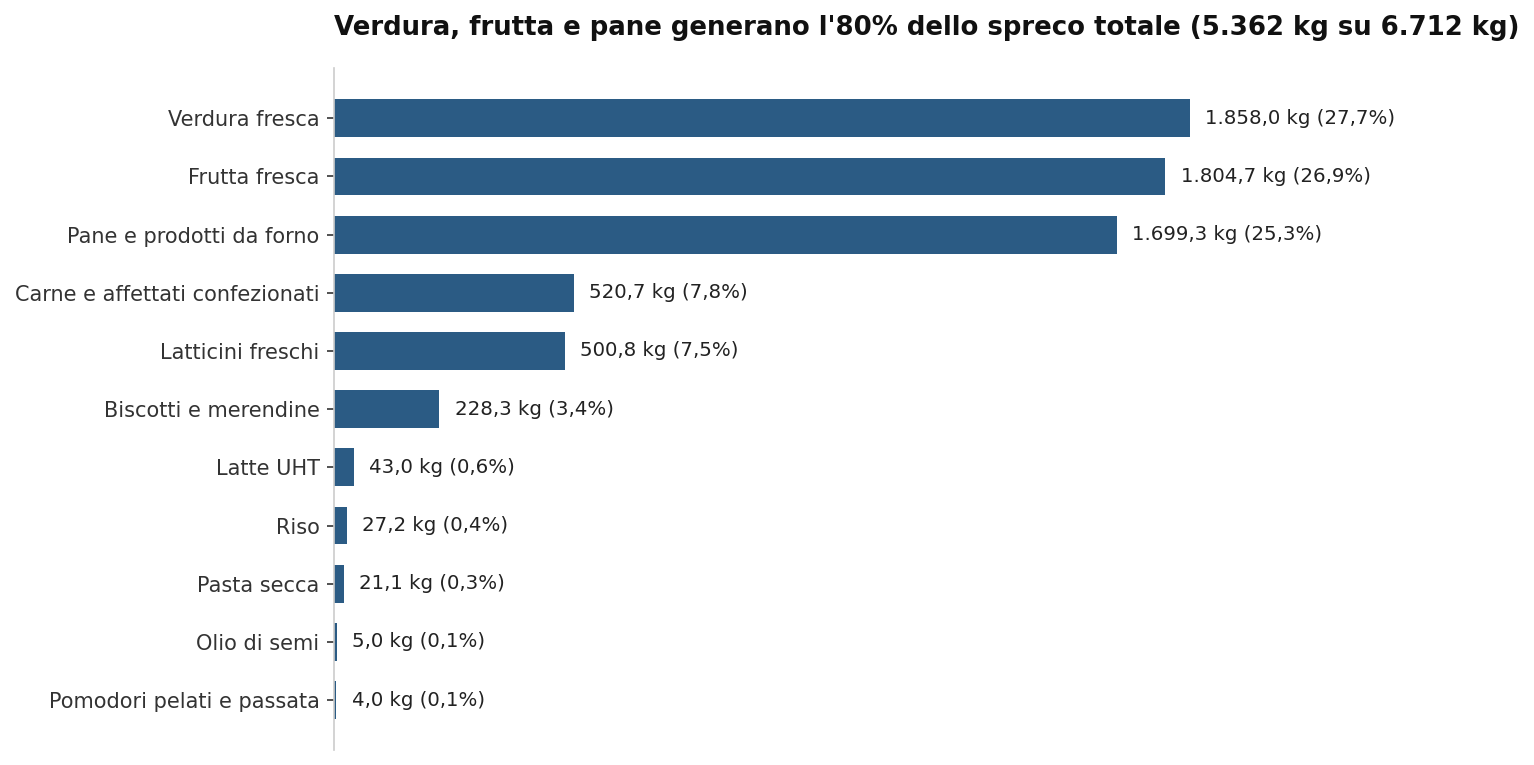

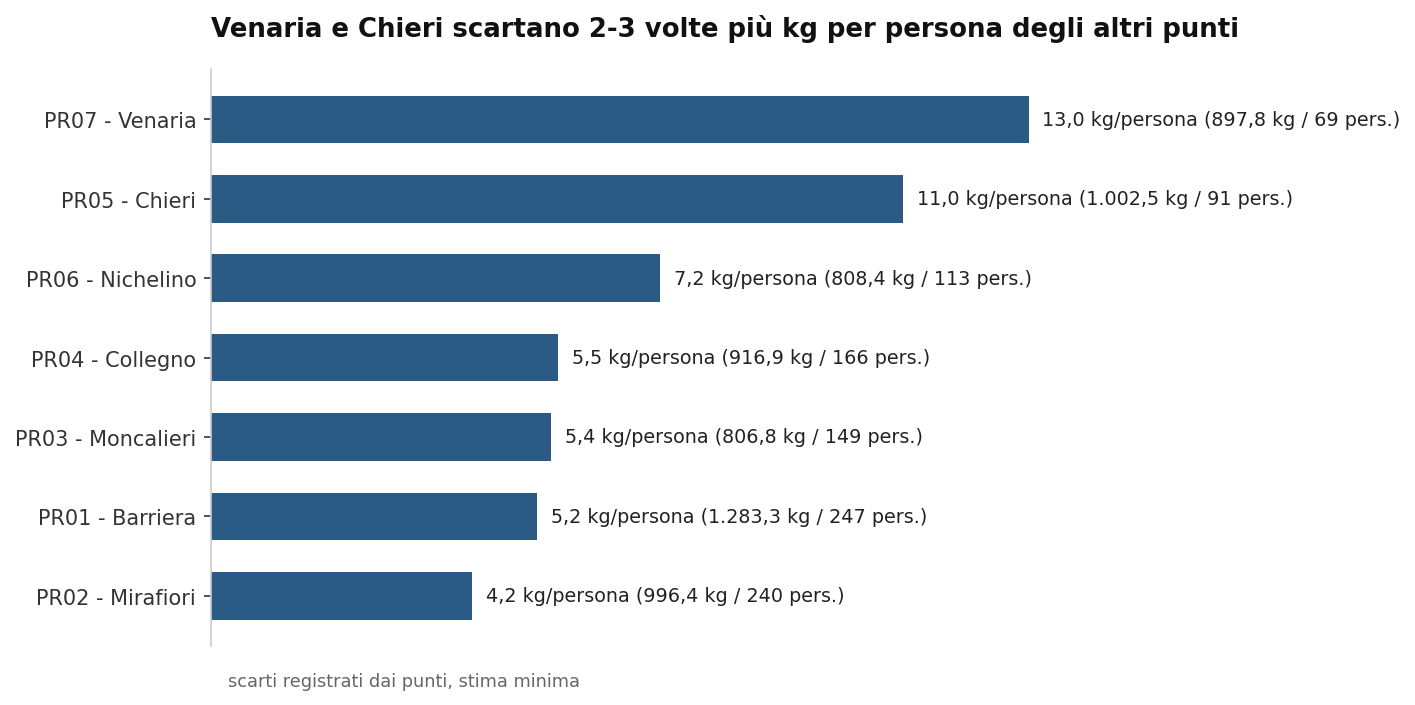

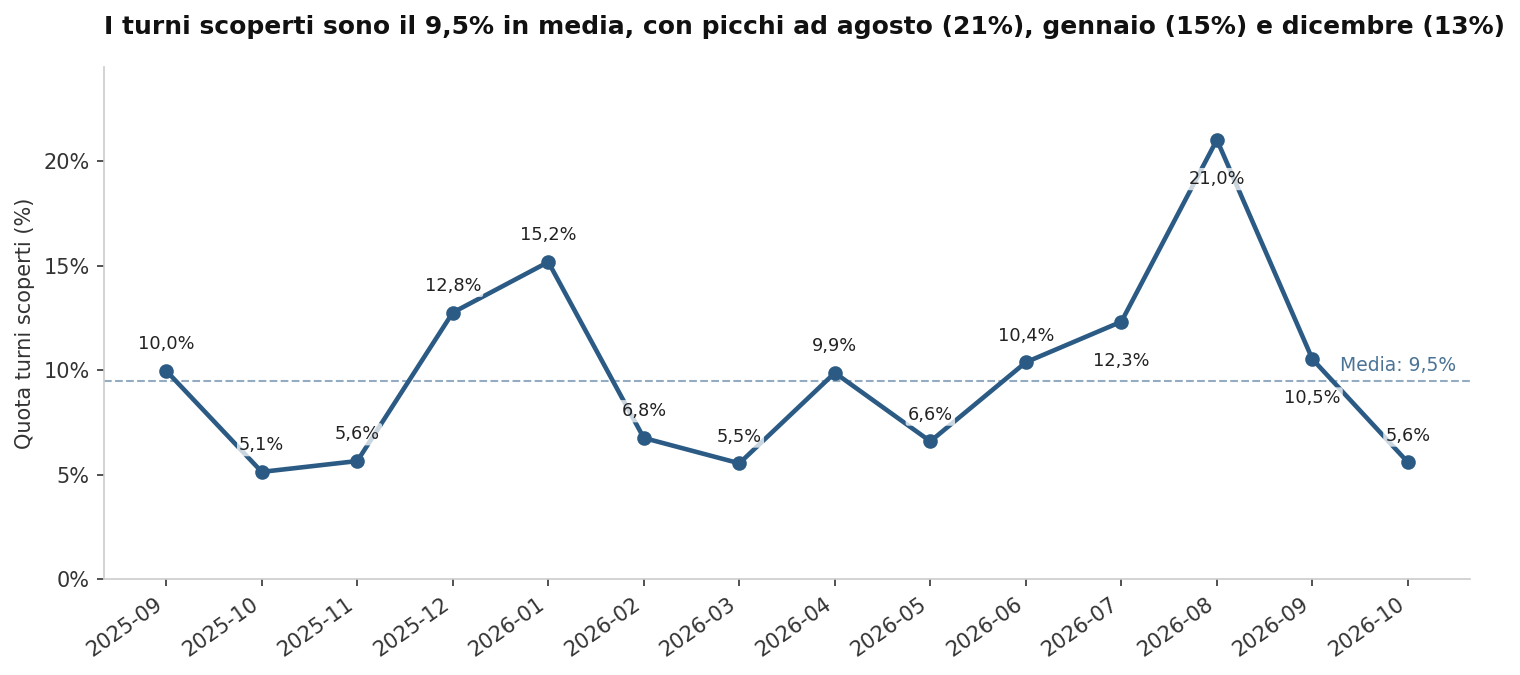

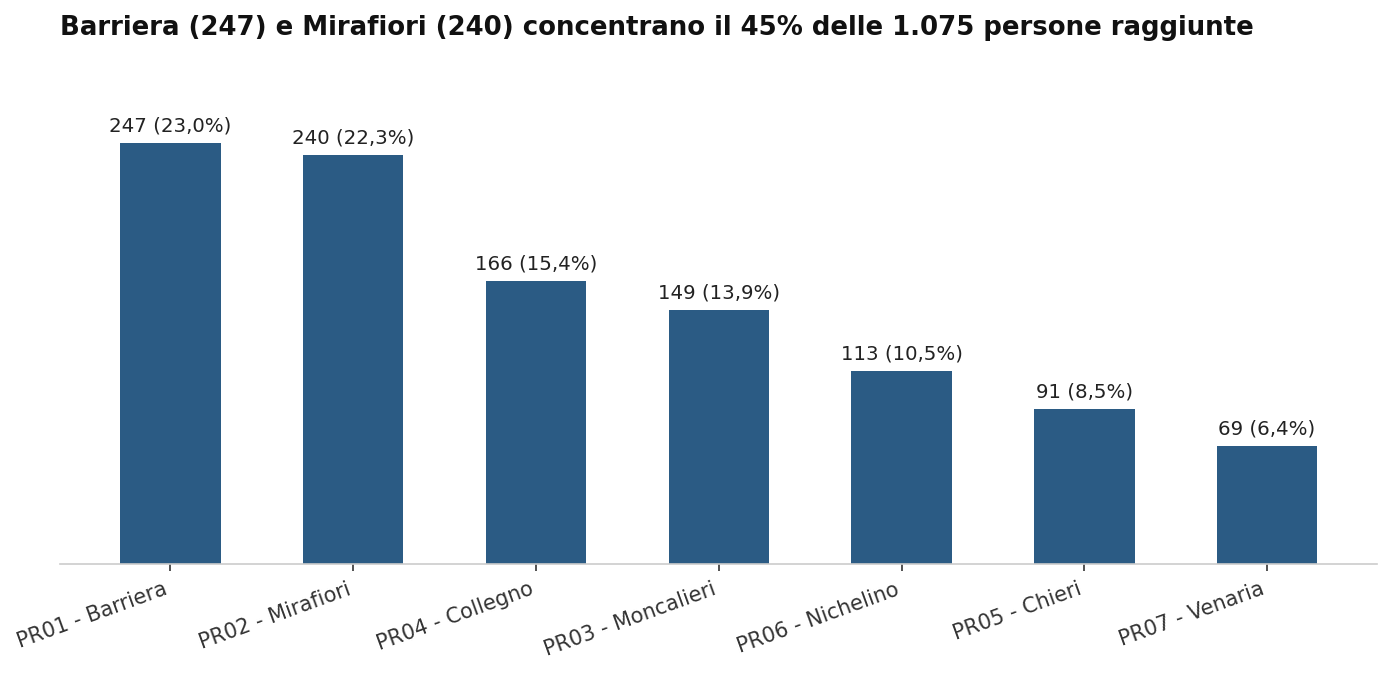

In [4]:
COLORE = "#2B5B84"
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8

def pulisci_assi(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)
    ax.tick_params(colors="#333333", labelsize=10)

# 1. spreco_categoria.png
cat_df = s_kg.groupby("categoria", as_index=False)["kg"].sum().sort_values("kg", ascending=False)
tot_kg = cat_df["kg"].sum()

fig, ax = plt.subplots(figsize=(9.5, 5.2), dpi=150)
bars = ax.barh(cat_df["categoria"], cat_df["kg"], color=COLORE, height=0.65)
ax.invert_yaxis()
pulisci_assi(ax)
ax.spines["bottom"].set_visible(False)
ax.xaxis.set_visible(False)
ax.set_xlim(0, cat_df["kg"].max() * 1.24)
for bar, val in zip(bars, cat_df["kg"]):
    ax.text(val + tot_kg * 0.005, bar.get_y() + bar.get_height()/2,
            f"{val:,.1f} kg ({val/tot_kg*100:.1f}%)".replace(",", "X").replace(".", ",").replace("X", "."),
            va="center", ha="left", fontsize=9.5, color="#222222")
ax.set_title("Verdura, frutta e pane generano l'80% dello spreco totale (5.362 kg su 6.712 kg)",
             fontsize=12.5, fontweight="bold", loc="left", pad=16, color="#111111")
plt.tight_layout()
plt.savefig("spreco_categoria.png", dpi=150)
plt.show()

# 2. spreco_punto.png (kg scartati per persona raggiunta)
kg_punto = s_kg.groupby("punto_id", as_index=False)["kg"].sum()
pers_punto = (
    attivi.groupby("punto_ritiro_riferimento", as_index=False)["n_componenti"]
    .sum()
    .rename(columns={"punto_ritiro_riferimento": "punto_id", "n_componenti": "persone"})
)

punto_s_df = pd.merge(kg_punto, pers_punto, on="punto_id")
punto_s_df["kg_per_persona"] = punto_s_df["kg"] / punto_s_df["persone"]
punto_s_df["etichetta"] = punto_s_df["punto_id"].map(NOMI_PUNTI)
punto_s_df = punto_s_df.sort_values("kg_per_persona", ascending=False)

fig, ax = plt.subplots(figsize=(9.5, 4.7), dpi=150)
bars = ax.barh(punto_s_df["etichetta"], punto_s_df["kg_per_persona"], color=COLORE, height=0.6)
ax.invert_yaxis()
pulisci_assi(ax)
ax.spines["bottom"].set_visible(False)
ax.xaxis.set_visible(False)
ax.set_xlim(0, punto_s_df["kg_per_persona"].max() * 1.32)

for bar, (_, row) in zip(bars, punto_s_df.iterrows()):
    val_str = f"{row['kg_per_persona']:.1f}".replace(".", ",")
    kg_str = f"{row['kg']:,.1f}".replace(",", "X").replace(".", ",").replace("X", ".")
    pers = int(row["persone"])
    ax.text(
        row["kg_per_persona"] + 0.22,
        bar.get_y() + bar.get_height() / 2,
        f"{val_str} kg/persona ({kg_str} kg / {pers} pers.)",
        va="center", ha="left", fontsize=9.2, color="#222222"
    )

ax.set_title(
    "Venaria e Chieri scartano 2-3 volte più kg per persona degli altri punti",
    fontsize=12.5, fontweight="bold", loc="left", pad=16, color="#111111"
)
fig.text(0.165, 0.015, "scarti registrati dai punti, stima minima", fontsize=8.5, color="#666666")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("spreco_punto.png", dpi=150)
plt.show()

# 3. turni_scoperti_mese.png
turni_mese_df = (
    t.groupby("mese", as_index=False)
    .agg(totale=("id_turno", "count"), scoperti=("stato", lambda x: (x == "scoperto").sum()))
    .sort_values("mese")
)
turni_mese_df["quota"] = turni_mese_df["scoperti"] / turni_mese_df["totale"] * 100
media_scoperti = (t["stato"] == "scoperto").mean() * 100

fig, ax = plt.subplots(figsize=(10, 4.6), dpi=150)
ax.plot(turni_mese_df["mese"], turni_mese_df["quota"], color=COLORE, marker="o", linewidth=2.2, markersize=6, zorder=3)
ax.axhline(media_scoperti, color=COLORE, linestyle="--", linewidth=1, alpha=0.5, zorder=2)
ax.text(len(turni_mese_df) - 0.5, media_scoperti + 0.45, f"Media: {media_scoperti:.1f}%".replace(".", ","),
        color=COLORE, fontsize=9, ha="right", alpha=0.85)

below_months = {"2026-07", "2026-08", "2026-09"}
for _, row in turni_mese_df.iterrows():
    m = row["mese"]
    offset_y, va = (-1.45, "top") if m in below_months else (0.85, "bottom")
    ax.text(m, row["quota"] + offset_y, f"{row['quota']:.1f}%".replace(".", ","),
            ha="center", va=va, fontsize=8.5, color="#222222",
            bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none", alpha=0.75))

pulisci_assi(ax)
ax.set_ylim(0, 24.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.xticks(rotation=35, ha="right")
ax.set_ylabel("Quota turni scoperti (%)", fontsize=10, color="#333333")
ax.set_title("I turni scoperti sono il 9,5% in media, con picchi ad agosto (21%), gennaio (15%) e dicembre (13%)",
             fontsize=12, fontweight="bold", loc="left", pad=16, color="#111111")
plt.tight_layout()
plt.savefig("turni_scoperti_mese.png", dpi=150)
plt.show()

# 4. persone_punto.png
pers_punto_df = (
    attivi.groupby("punto_ritiro_riferimento", as_index=False)
    .agg(persone=("n_componenti", "sum"))
    .sort_values("persone", ascending=False)
)
pers_punto_df["etichetta"] = pers_punto_df["punto_ritiro_riferimento"].map(NOMI_PUNTI)
tot_persone = pers_punto_df["persone"].sum()

fig, ax = plt.subplots(figsize=(9.5, 4.6), dpi=150)
bars = ax.bar(pers_punto_df["etichetta"], pers_punto_df["persone"], color=COLORE, width=0.55)
pulisci_assi(ax)
ax.spines["left"].set_visible(False)
ax.yaxis.set_visible(False)
ax.set_ylim(0, pers_punto_df["persone"].max() * 1.18)
plt.xticks(rotation=20, ha="right")
for bar, val in zip(bars, pers_punto_df["persone"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 5,
            f"{int(val)} ({val/tot_persone*100:.1f}%)".replace(".", ","),
            ha="center", va="bottom", fontsize=9.5, color="#222222")
ax.set_title("Barriera (247) e Mirafiori (240) concentrano il 45% delle 1.075 persone raggiunte",
             fontsize=12.5, fontweight="bold", loc="left", pad=16, color="#111111")
plt.tight_layout()
plt.savefig("persone_punto.png", dpi=150)
plt.show()

In [5]:
from google.colab import files
for nome_file in ["spreco_categoria.png", "spreco_punto.png", "turni_scoperti_mese.png", "persone_punto.png"]:
    files.download(nome_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>